# NB03 — Baseline LSTM et Entraînement Autorégressif
> **Projet 1.1 — Phase C & D** : Modèle récurrent avec Weight Tying (Bengio et al. 2003, Hochreiter & Schmidhuber 1997).

| | Chemin |
|---|---|
| **Entrées** | `data/processed/<DATA_VERSION>/{train.csv, val.csv}` (produits par NB02) |
| **Sorties** | `models/lstm-notebook/best.pt`, `results/runs/lstm-notebook/history.csv` |

Ce notebook implémente la première baseline neuronale du projet :
1. **Modèle LSTM autorégressif** avec partage des poids (Weight Tying) : `head.weight = embed.weight`.
2. **Initialisation adaptée** : `nn.init.normal_(self.embed.weight, mean=0.0, std=0.1)` (évite une loss initiale aberrante).
3. **Chargement robuste des données** : lit `processed/<DATA_VERSION>/` en local (`toy`) ou sur Google Colab (`SRR3544218` ou `v1`).
4. **Entraînement avec scheduler** : warmup linéaire + décroissance en cosinus, AdamW, gradient clipping.
5. **Évaluation rigoureuse** : nats/token et perplexité calculés exactement (somme des NLL divisée par le nombre total de tokens réels, conforme à la baseline bigram).
6. **Courbes d'apprentissage** : tracé de l'évolution de la loss sur train et val.
7. **Génération de séquences** : échantillonnage pas à pas via `sampling.py` et validation biologique des séquences générées.


In [1]:
# ==============================================================================
# Cellule 1 : RÉGLAGES + Bootstrap (local ET Google Colab), Drive, chemins, imports
# ==============================================================================
# ------------------------------ RÉGLAGES -------------------------------------
# Nom du jeu de données (dossier data/processed/<nom>/)
#   None -> automatique : 'toy' en local, 'SRR3544218' ou 'v1' sur Colab.
DATA_VERSION_OVERRIDE = None

# Hyperparamètres
SEED = 42
BATCH_SIZE = 64
EMBED_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 1
LR = 1e-3
WEIGHT_DECAY = 0.01
EPOCHS = 10
GRAD_CLIP = 1.0
WARMUP = 100
PATIENCE = 3
# ------------------------------------------------------------------------------
import os, sys, json, math, time, subprocess
from pathlib import Path

REPO_URL = "https://github.com/AhmadBelhaj4/Recherche_AI.git"
BRANCH = "b/sprint2-training"


def _find_root(start):
    """Remonte depuis `start` jusqu'au dossier qui contient utils.py et models.py."""
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "utils.py").exists() and (p / "models.py").exists():
            return p
        if (p / "project1" / "utils.py").exists():
            return p / "project1"
    return None


try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT_DIR = _find_root(Path.cwd())

if ROOT_DIR is None and IN_COLAB:
    clone_target = Path("/content/Recherche_AI")
    if not clone_target.exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(clone_target)], check=True)
    ROOT_DIR = _find_root(clone_target)

if ROOT_DIR is None:
    raise FileNotFoundError("utils.py introuvable : ouvrez le notebook dans le dépôt Recherche_AI.")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _drive = Path("/content/drive/MyDrive/AI_Project_Shared")
    if not _drive.exists():
        raise FileNotFoundError(f"Dossier Drive introuvable : {_drive}. Ajoutez le raccourci dans 'Mon Drive'.")
    os.environ.setdefault("AI_PROJECT_DIR", str(_drive))

sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from utils import (get_paths, get_data_version, get_device, set_seed,
                   AminoAcidTokenizer, make_loader, shift, compute_nats_and_perplexity,
                   VOCAB_SIZE, PAD_ID, BOS_ID, EOS_ID, is_valid_sequence)
from models import LSTMLM
from training import evaluate, lr_at, count_params, load_split
from sampling import generate

set_seed(SEED)
device = get_device()
PATHS = get_paths()
DATA_VERSION = DATA_VERSION_OVERRIDE or get_data_version()
DATA_DIR = PATHS["processed"] / DATA_VERSION

print(f"MODE         : {'DONNÉES RÉELLES (Colab / Drive)' if DATA_VERSION != 'toy' else 'TOY (local, fausses données)'}")
print(f"DATA_VERSION : {DATA_VERSION}")
print(f"Dossier data : {DATA_DIR}")
print(f"Device       : {device}")
print(f"Seed: {SEED} | Batch: {BATCH_SIZE} | LR: {LR} | Epochs: {EPOCHS}")


MODE         : TOY (local, fausses données)
DATA_VERSION : toy
Dossier data : C:\Users\GMI\Desktop\My_Projects\reacherche_ai\data\toy\processed\toy
Device       : cpu
Seed: 42 | Batch: 64 | LR: 0.001 | Epochs: 10


## 2. Architecture LSTM avec Weight Tying (Bengio et al. 2003)
Le modèle LSTM prédit le prochain acide aminé conditionné par l'historique des tokens vus.
Le partage des poids (*weight tying*) lie la matrice d'embedding d'entrée et la matrice de projection de sortie : `self.head.weight = self.embed.weight`.
L'initialisation normale `std=0.1` garantit une loss initiale équilibrée (~3.14 nats ≈ ln(23)).


In [2]:
# ==============================================================================
# Cellule 2 : Instanciation du modèle LSTMLM
# ==============================================================================
model = LSTMLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, NUM_LAYERS).to(device)
n_params = count_params(model)

print(f"Modèle LSTM instancié sur {device} :")
print(f"- Paramètres entraînables : {n_params:,}")
print(f"- Architecture           : embed_dim={EMBED_DIM}, hidden_dim={HIDDEN_DIM}, num_layers={NUM_LAYERS}")
print(f"- Weight tying actif     : {model.head.weight is model.embed.weight}")


Modèle LSTM instancié sur cpu :
- Paramètres entraînables : 431,104
- Architecture           : embed_dim=128, hidden_dim=256, num_layers=1
- Weight tying actif     : True


## 3. Chargement des Données (Train & Validation)
Lecture de `data/processed/<DATA_VERSION>/train.csv` et `val.csv`. Le jeu de test reste scellé jusqu'à l'évaluation finale.


In [3]:
# ==============================================================================
# Cellule 3 : Chargement des données et DataLoaders
# ==============================================================================
train_path = DATA_DIR / "train.csv"
val_path = DATA_DIR / "val.csv"

# Auto-génération en mode toy si nécessaire
if (not train_path.exists() or not val_path.exists()) and DATA_VERSION == "toy":
    print("Génération automatique des données toy...")
    subprocess.run([sys.executable, str(ROOT_DIR / "scripts" / "make_toy_data.py")], check=True)

train_seqs = load_split(DATA_VERSION, "train")
val_seqs = load_split(DATA_VERSION, "val")

tok = AminoAcidTokenizer()
train_loader = make_loader(train_seqs, tok, batch_size=BATCH_SIZE, shuffle=True, seed=SEED)
val_loader = make_loader(val_seqs, tok, batch_size=BATCH_SIZE, shuffle=False)

print(f"Données prêtes ({DATA_VERSION}) :")
print(f"- Train : {len(train_seqs):,} séquences ({len(train_loader)} batchs)")
print(f"- Val   : {len(val_seqs):,} séquences ({len(val_loader)} batchs)")
print(f"- Longueurs Train : min={min(len(s) for s in train_seqs)}, moy={np.mean([len(s) for s in train_seqs]):.1f}, max={max(len(s) for s in train_seqs)}")


Données prêtes (toy) :
- Train : 180 séquences (3 batchs)
- Val   : 10 séquences (1 batchs)
- Longueurs Train : min=110, moy=120.5, max=130


## 4. Boucle d'Entraînement avec Scheduler & Checkpointing
- Optimiseur : **AdamW** avec weight decay = 0.01
- Scheduler : **Warmup linéaire** (100 pas) puis **décroissance en cosinus** jusqu'à 10% du LR
- Gradient clipping : 1.0 (évite l'explosion des gradients)
- Checkpoints : sauvegarde de `best.pt` sur le meilleur score de validation


In [4]:
# ==============================================================================
# Cellule 4 : Entraînement de LSTMLM
# ==============================================================================
RUN_ID = f"lstm-notebook-{DATA_VERSION}"
ckpt_dir = PATHS["models"] / RUN_ID
res_dir = PATHS["results"] / "runs" / RUN_ID
ckpt_dir.mkdir(parents=True, exist_ok=True)
res_dir.mkdir(parents=True, exist_ok=True)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
crit = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")
total_steps = EPOCHS * len(train_loader)

history = []
best_val_nats = float("inf")
best_epoch = 0
best_path = ckpt_dir / "best.pt"

print(f"Début de l'entraînement LSTM ({EPOCHS} époques)...")
t_start = time.time()
step = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0 = time.time()
    tot_loss, tot_tokens = 0.0, 0
    for batch in train_loader:
        x, y = shift(batch)
        x, y = x.to(device), y.to(device)
        current_lr = lr_at(step, total_steps, LR, WARMUP)
        for g in opt.param_groups:
            g["lr"] = current_lr
        opt.zero_grad(set_to_none=True)
        logits, _ = model(x)
        loss_sum = crit(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1))
        n = (y != PAD_ID).sum()
        loss = loss_sum / n.clamp(min=1)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        opt.step()
        tot_loss += loss_sum.item()
        tot_tokens += n.item()
        step += 1

    train_nats, train_ppl = compute_nats_and_perplexity(tot_loss, tot_tokens)
    val_nats, val_ppl = evaluate(model, val_loader, device)
    elapsed = time.time() - t0
    
    improved = val_nats < best_val_nats
    if improved:
        best_val_nats = val_nats
        best_epoch = epoch
        torch.save({
            "state_dict": model.state_dict(),
            "config": dict(model="lstm", embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS),
            "epoch": epoch,
            "val_nats": val_nats
        }, best_path)
    
    history.append({
        "epoch": epoch, "train_nats": train_nats, "train_ppl": train_ppl,
        "val_nats": val_nats, "val_ppl": val_ppl, "lr": current_lr, "seconds": elapsed
    })
    
    star = "★" if improved else ""
    print(f"Epoch {epoch:2d}/{EPOCHS} | Train {train_nats:.4f} (ppl {train_ppl:.2f}) | Val {val_nats:.4f} (ppl {val_ppl:.2f}) {star} | {elapsed:.1f}s")

pd.DataFrame(history).to_csv(res_dir / "history.csv", index=False)
print(f"\n✅ Entraînement terminé en {time.time() - t_start:.1f}s.")
print(f"Meilleur modèle sauvegardé dans {best_path} (epoch {best_epoch}, val nats {best_val_nats:.4f}, ppl {math.exp(best_val_nats):.2f})")


Début de l'entraînement LSTM (10 époques)...
Epoch  1/10 | Train 3.1340 (ppl 22.97) | Val 3.1324 (ppl 22.93) ★ | 0.8s
Epoch  2/10 | Train 3.1332 (ppl 22.95) | Val 3.1311 (ppl 22.90) ★ | 0.6s
Epoch  3/10 | Train 3.1317 (ppl 22.91) | Val 3.1290 (ppl 22.85) ★ | 0.6s
Epoch  4/10 | Train 3.1293 (ppl 22.86) | Val 3.1261 (ppl 22.79) ★ | 0.6s
Epoch  5/10 | Train 3.1263 (ppl 22.79) | Val 3.1225 (ppl 22.70) ★ | 0.7s
Epoch  6/10 | Train 3.1225 (ppl 22.70) | Val 3.1181 (ppl 22.60) ★ | 0.6s
Epoch  7/10 | Train 3.1178 (ppl 22.60) | Val 3.1125 (ppl 22.48) ★ | 0.6s
Epoch  8/10 | Train 3.1118 (ppl 22.46) | Val 3.1053 (ppl 22.32) ★ | 0.7s
Epoch  9/10 | Train 3.1039 (ppl 22.29) | Val 3.0954 (ppl 22.10) ★ | 0.5s
Epoch 10/10 | Train 3.0928 (ppl 22.04) | Val 3.0805 (ppl 21.77) ★ | 0.6s

✅ Entraînement terminé en 6.3s.
Meilleur modèle sauvegardé dans C:\Users\GMI\Desktop\My_Projects\reacherche_ai\models\lstm-notebook-toy\best.pt (epoch 10, val nats 3.0805, ppl 21.77)


## 5. Visualisation des Courbes d'Apprentissage
Tracé de l'évolution de la perte en nats/token au fil des époques, comparée aux références (Uniforme = ln(20) ≈ 2.996 nats, PPL 20.0).


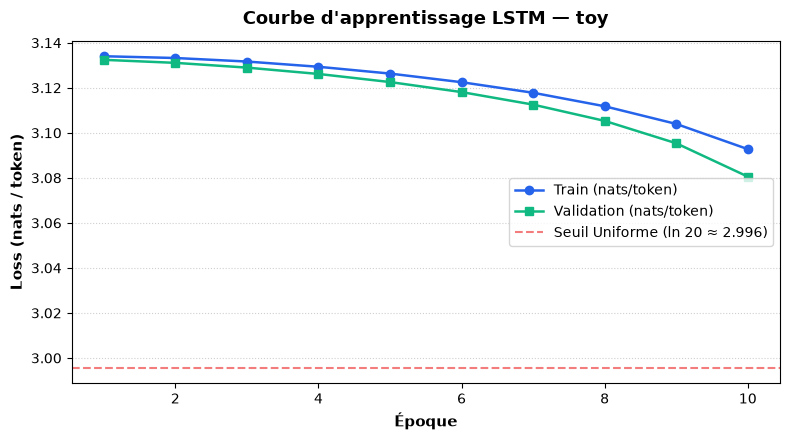

In [5]:
# ==============================================================================
# Cellule 5 : Courbes d'apprentissage Train vs Val
# ==============================================================================
epochs_range = [h["epoch"] for h in history]
train_curve = [h["train_nats"] for h in history]
val_curve = [h["val_nats"] for h in history]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs_range, train_curve, marker="o", label="Train (nats/token)", color="#2563eb", linewidth=1.8)
ax.plot(epochs_range, val_curve, marker="s", label="Validation (nats/token)", color="#10b981", linewidth=1.8)
ax.axhline(math.log(20), color="#ef4444", linestyle="--", alpha=0.7, label=f"Seuil Uniforme (ln 20 ≈ {math.log(20):.3f})")
ax.set_xlabel("Époque", fontsize=11, fontweight="bold")
ax.set_ylabel("Loss (nats / token)", fontsize=11, fontweight="bold")
ax.set_title(f"Courbe d'apprentissage LSTM — {DATA_VERSION}", fontsize=13, fontweight="bold", pad=12)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Génération et Validation de Séquences VHH
Échantillonnage de séquences avec le meilleur modèle rechargé via `sampling.generate`.
Contrôle de la validité biologique (longueur 100-140, 20 acides aminés standard, terminaison par `<EOS>`).


In [6]:
# ==============================================================================
# Cellule 6 : Génération et contrôle des séquences produites
# ==============================================================================
print(f"Rechargement du meilleur checkpoint : {best_path}...")
ck = torch.load(best_path, map_location=device)
model.load_state_dict(ck["state_dict"])
model.eval()

N_GEN = 10
print(f"Génération de {N_GEN} séquences (T=1.0, seed={SEED}) :\n")
seqs, done = generate(model, N_GEN, device, max_len=140, temperature=1.0, seed=SEED)

for i, (s, d) in enumerate(zip(seqs, done), 1):
    valid = is_valid_sequence(s) if s else False
    status = "✅ Valide" if valid else "⚠️ Hors bornes/Invalide"
    eos_info = "EOS" if d else "Tronquée (max_len)"
    print(f"[{i:02d}] {status} ({eos_info}) | L={len(s):>3} aa : {s[:65]}...")

valid_rate = np.mean([is_valid_sequence(s) for s in seqs])
print(f"\nTaux de validité biologique : {valid_rate:.1%}")
print(f"Taux de terminaison par EOS : {np.mean(done):.1%}")


Rechargement du meilleur checkpoint : C:\Users\GMI\Desktop\My_Projects\reacherche_ai\models\lstm-notebook-toy\best.pt...
Génération de 10 séquences (T=1.0, seed=42) :

[01] ✅ Valide (EOS) | L=116 aa : EHQHGIIRNTLNCKDSQTNMVEGVTGVQCSHEIWILWLTELQIWAQCNQTMNVADIRPFQPATMK...
[02] ⚠️ Hors bornes/Invalide (EOS) | L= 26 aa : RHKPLAFVQCTTVDMSIKKKKQKVNT...
[03] ⚠️ Hors bornes/Invalide (EOS) | L= 58 aa : RQNHLTKDRVNNCWWWSWKSMYYHFAKQRPVNYTVANNHKHQFLQTRWTRRHQNTCHL...
[04] ⚠️ Hors bornes/Invalide (EOS) | L= 42 aa : HNITLNIDWSSAWSCEPFCGMILITSTQTFWAEQIKSYEKNG...
[05] ✅ Valide (Tronquée (max_len)) | L=140 aa : HKPIDPIDPMCGQTLPTKYEYNPNGNEVKATLCCWFWIPRHDFTAMAWNELDDAHFWGNTYSDDQ...
[06] ⚠️ Hors bornes/Invalide (EOS) | L= 31 aa : RIRVCWGEFRQMGTCYACLIHIPHKWDDTKN...
[07] ⚠️ Hors bornes/Invalide (EOS) | L= 45 aa : DPLMKKHANVDPQPMANKIMSDAKQTNREIKPPTRTLNRYEVVEL...
[08] ⚠️ Hors bornes/Invalide (EOS) | L=  3 aa : TGY...
[09] ⚠️ Hors bornes/Invalide (EOS) | L= 12 aa : WAHSNMLDYLDR...
[10] ⚠️ Hors bornes/Invalide (EO

## 7. Sauvegarde Hybride (Google Colab ⟷ BioLM Studio Dashboard)

Cette cellule sauvegarde le modèle selon les **bonnes pratiques ML** :
1. Les **métriques légères** (`config.json`, `metrics.json`, `history.csv`, et échantillons générés) sont enregistrées dans `results/runs/{RUN_ID}/` pour Git et le Dashboard.
2. Le **checkpoint lourd** (`best.pt`) est sauvegardé de manière sécurisée dans votre **Google Drive** (`MyDrive/recherche_ai_models/{RUN_ID}/best.pt`).
3. Prêt à être visualisé et testé dans **BioLM Studio** (`http://localhost:8765`).


In [ ]:
# ==============================================================================
# Cellule 7 : Export Hybride pour Google Colab & BioLM Studio
# ==============================================================================
import sys
from pathlib import Path

# Assure l'accès au module colab_sync depuis le dossier parent
if str(Path.cwd().parent.parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent.parent))

from colab_sync import save_colab_run

config_dict = {
    "run_id": RUN_ID,
    "data_version": DATA_VERSION,
    "seed": SEED,
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "weight_decay": WEIGHT_DECAY,
    "model_config": {
        "model": "lstm",
        "embed_dim": EMBED_DIM,
        "hidden_dim": HIDDEN_DIM,
        "num_layers": NUM_LAYERS
    },
    "n_params": sum(p.numel() for p in model.parameters() if p.requires_grad)
}

metrics_summary = save_colab_run(
    run_id=RUN_ID,
    model=model,
    history=history,
    config=config_dict,
    device=device,
    sync_drive=True,          # Copie best.pt dans Google Drive si sous Colab
    push_git=False,           # Mettre à True si un token Git est configuré dans Colab
    n_samples=5,              # Génère 5 séquences de test pour le dashboard
    auto_download_zip=False   # Mettre à True pour télécharger l'archive zip en 1 clic
)
